 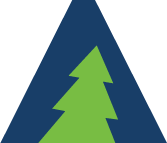 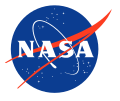 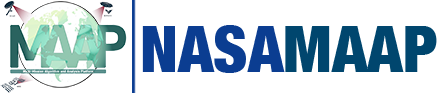   
| --- | These products were developed with funding from the [NASA Arctic Boreal Vulnerability Experiment (ABoVE)](https://above.nasa.gov/). |
| ----------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| ---| Code development and data processing are performed on the [NASA Multi-Mission Algorithm and Analysis Platform](https://maap-project.org) |  

# Circumpolar taiga-tundra ecotone map from the `NASA ABoVE Boreal Biomass Mapping` project
### Interactive maps shown: 
+ TTE classification (Montesano et al. 2020 https://doi.org/10.1088/1748-9326/abb2c7)
+ CAVM northern treeline for context (Walker et al. 2005 https://doi.org/10.1111/j.1654-1103.2005.tb02365.x)


<table style="width:50%; table-layout:fixed; margin-left:0;">
  <tr>
    <th align="center" style="width:50%;">TTE classification</th>
  </tr>
  <tr>
    <td align="center">
      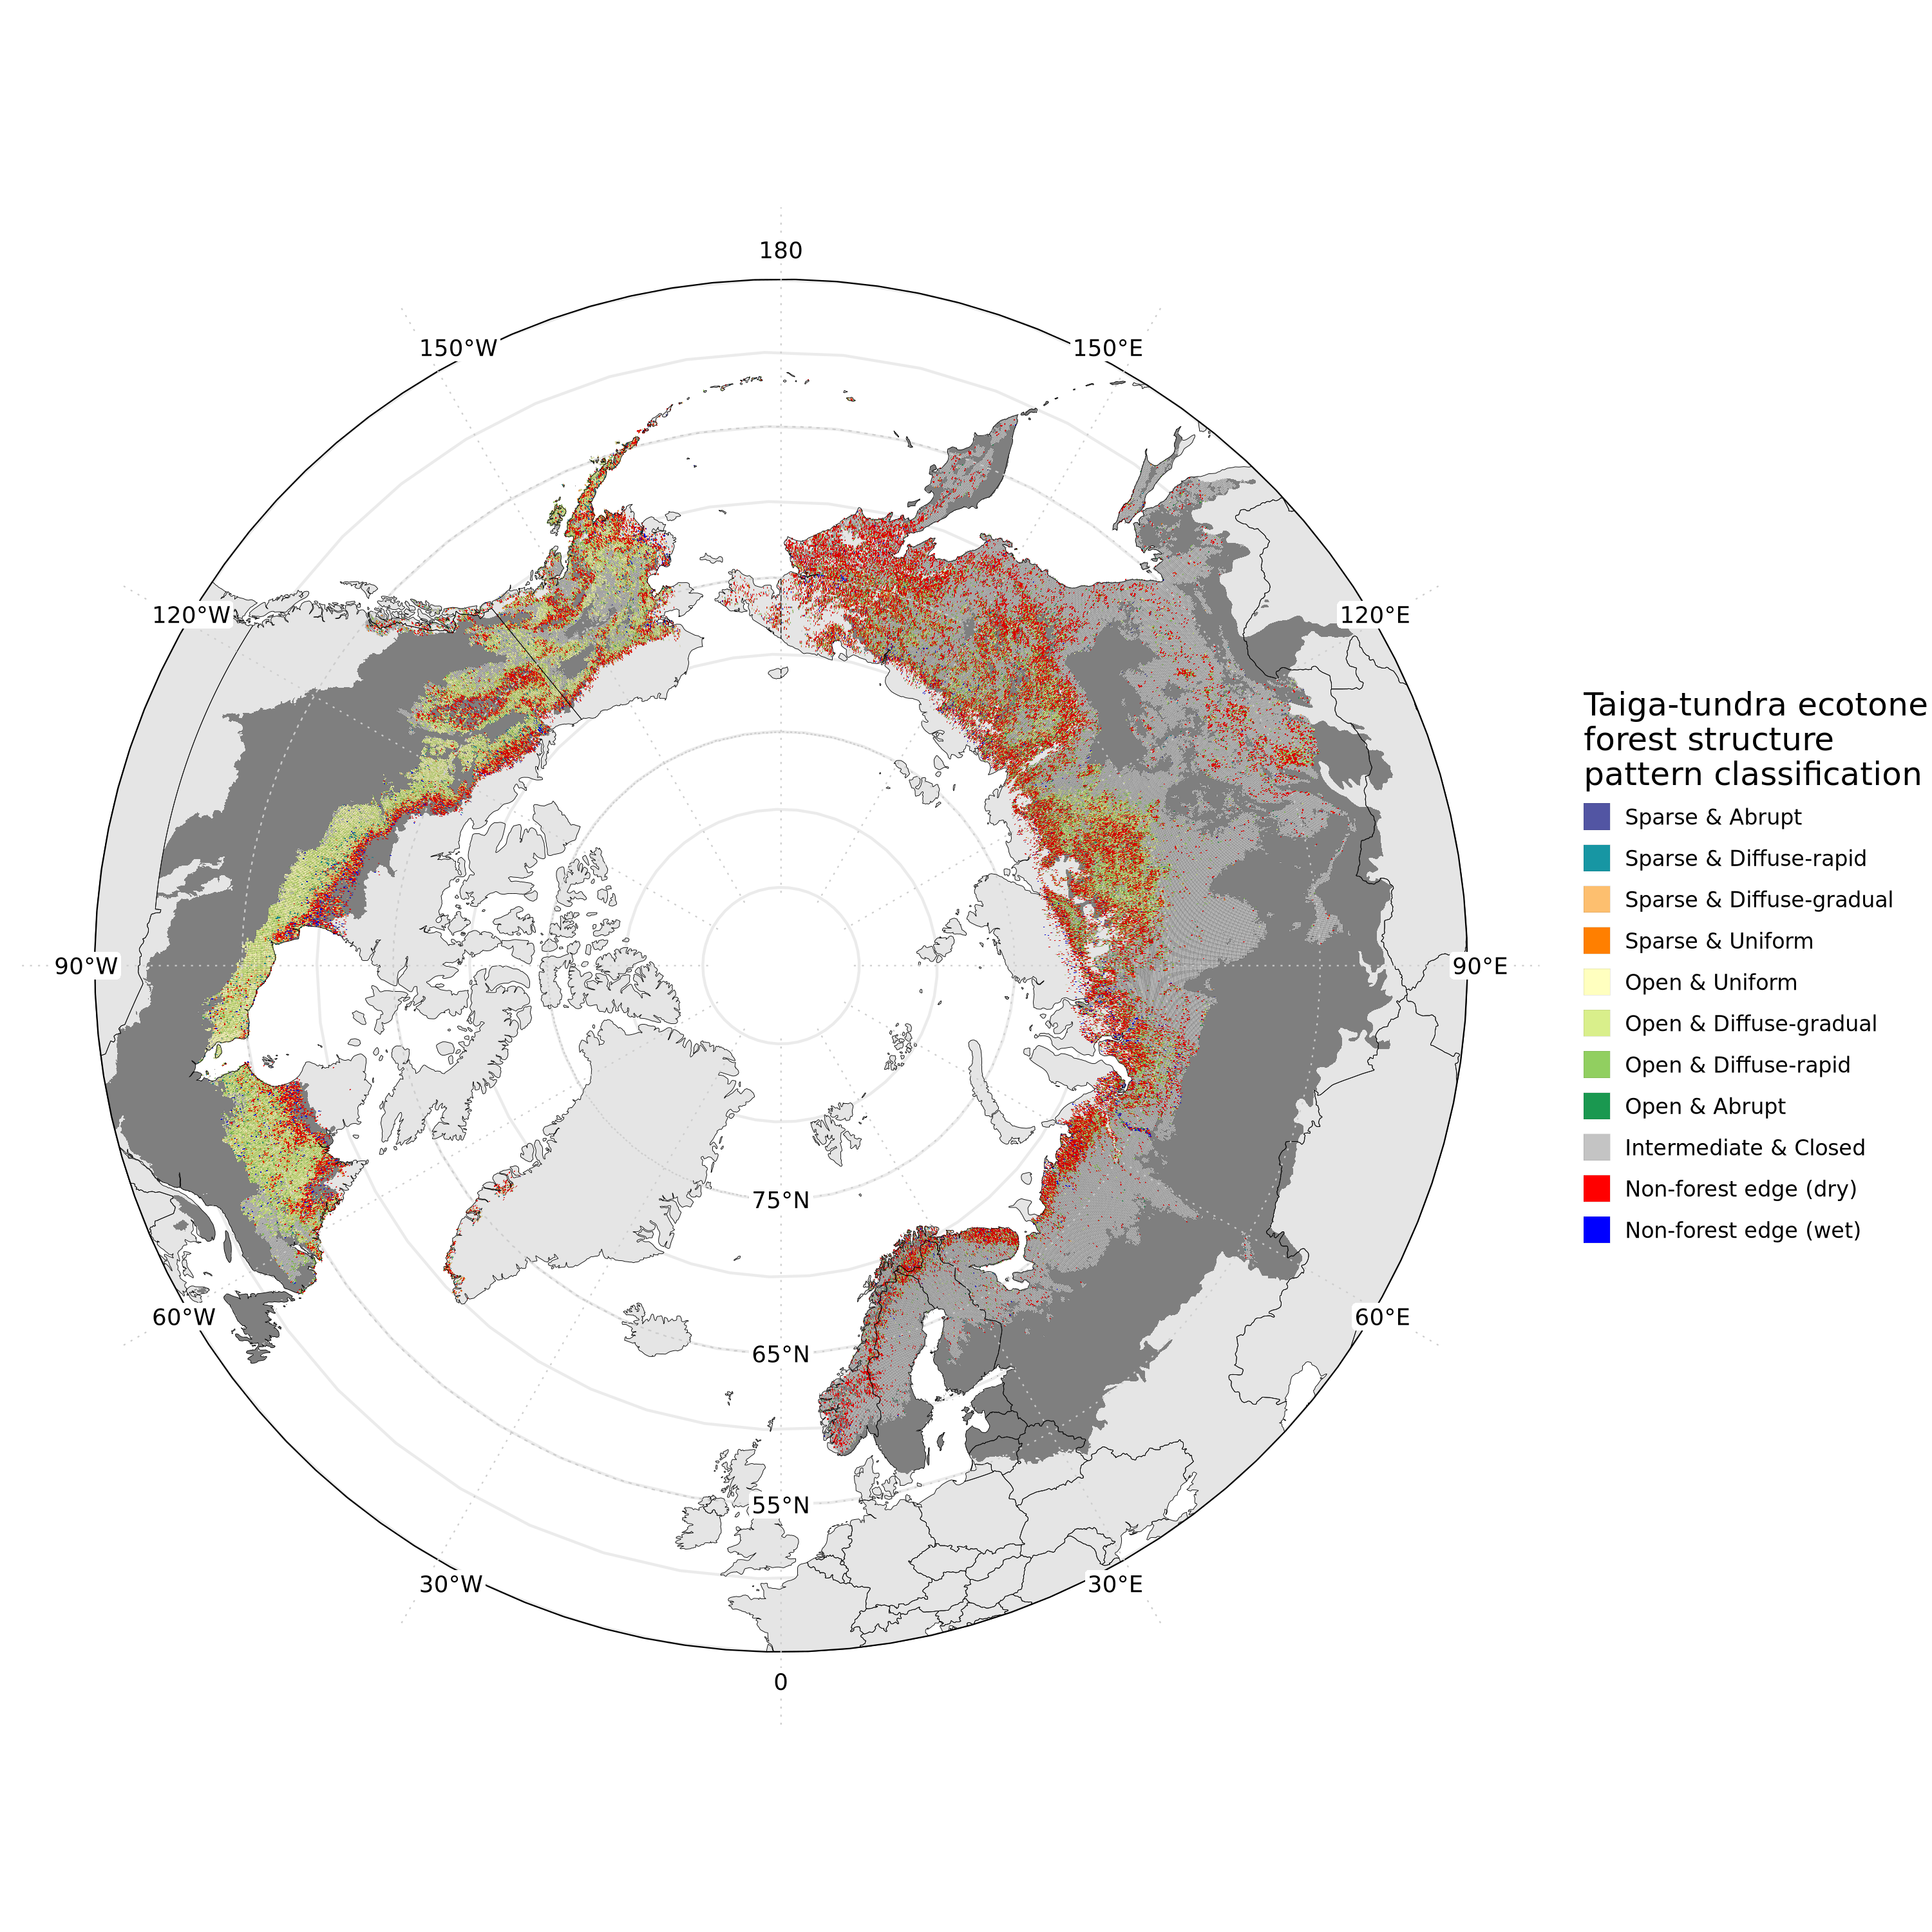
    </td>
  </tr>
</table>

| Contributors | Role | Affiliation | 
| ---------------- | ---------------- | ---------------- |
| Paul Montesano paul.m.montesano@nasa.gov |  Co-I | NASA Goddard Space Flight Center, ESSIC - U. Maryland |

In [1]:
!pip install cogeo_mosaic==8.2.0

In [2]:
# from maap.maap import MAAP
# maap = MAAP()
import geopandas
import pandas as pd
import os
import sys
import importlib

ICESAT2_BOREAL_LIB_PATH = '/projects/my-private-bucket/code/icesat2_boreal/lib'   
sys.path.append(ICESAT2_BOREAL_LIB_PATH)
import maplib_folium
import mosaiclib
from mosaiclib import *

# Shared Review map page template (maap_tools/lib)
sys.path.append(os.path.abspath(os.path.join('..', 'lib')))
import review_maps
review_maps.use_mosaic_registry(maplib_folium)   # reuse TiTiler mosaic ids so tile urls stay stable across reruns

In [3]:
import urllib.parse, json
from matplotlib.colors import to_rgb
import branca

# Map
Note: zoom-in to display map tiles

In [4]:
boreal_tiles = geopandas.read_file(boreal_tile_index_path)

In [5]:
import importlib
importlib.reload(mosaiclib)
importlib.reload(maplib_folium)
review_maps.use_mosaic_registry(maplib_folium)   # re-apply after the reload

In [6]:
import json
from matplotlib.colors import to_rgb

# --- TTE class definitions (mirroring your R dicts) ---
tte_classes_dict = {
    1:  "Sparse & Abrupt",
    2:  "Sparse & Diffuse-rapid",
    3:  "Sparse & Diffuse-gradual",
    4:  "Sparse & Uniform",
    5:  "Open & Uniform",
    6:  "Open & Diffuse-gradual",
    7:  "Open & Diffuse-rapid",
    8:  "Open & Abrupt",
    9:  "Intermediate & Closed",
    10: "Non-forest edge (dry)",
    11: "Non-forest edge (wet)",
}

tte_colors_dict = {
    1:  "#5255a3",
    2:  "#1796a3",
    3:  "#fdbf6f",
    4:  "#ff7f00",
    5:  "#ffffbf",
    6:  "#d9ef8b",
    7:  "#91cf60",
    8:  "#1a9850",
    9:  "#c4c4c4",
    10: "#ff0000",
    11: "#0000ff",
}

# --- Build the TiTiler categorical colormap ---
# TiTiler expects: {pixel_value: [R, G, B, A]} with values 0-255, JSON-encoded
def hex_to_rgba(hex_color, alpha=255):
    r, g, b = [int(c * 255) for c in to_rgb(hex_color)]
    return [r, g, b, alpha]

tte_titiler_cmap = {
    str(val): hex_to_rgba(hex_col)
    for val, hex_col in tte_colors_dict.items()
}

# JSON-encode for the URL parameter
tte_cmap_json = json.dumps(tte_titiler_cmap)

In [7]:
legend_title = (
    "Taiga-tundra ecotone<br>"
    "forest structure<br>"
    "pattern classification"
    '<br><span style="font-size:9px; font-weight:normal;">'
    'Montesano et al. 2020 '
    '<a href="https://doi.org/10.1088/1748-9326/abb2c7" '
    'target="_blank" style="color:#0645ad; text-decoration:none;">'
    'doi:10.1088/1748-9326/abb2c7</a>'
    '</span>'
)
rows = "".join(
    f'<div style="display:flex;align-items:center;margin:2px 0;">'
    f'  <span style="background:{tte_colors_dict[v]};width:18px;height:14px;'
    f'               display:inline-block;border:1px solid #555;margin-right:6px;"></span>'
    f'  <span style="font-size:11px;">{v}: {tte_classes_dict[v]}</span>'
    f'</div>'
    for v in sorted(tte_classes_dict)
)

legend_html = f"""
<div style="
    position: absolute;
    top: 20px; left: 20px;
    z-index: 9999;
    background: rgba(255,255,255,0.92);
    padding: 8px 10px;
    border: 1px solid #888;
    border-radius: 4px;
    font-family: sans-serif;
    max-height: 320px; overflow-y: auto;">
  <div style="font-weight:bold; font-size:12px; line-height:1.25; margin-bottom:6px;">
    {legend_title}
  </div>
  {rows}
  {review_maps.TREELINE_LEGEND_ROW}
</div>
"""

In [8]:
def hex_to_rgba(hex_color, alpha=255):
    r, g, b = [int(c * 255) for c in to_rgb(hex_color)]
    return [r, g, b, alpha]

def make_categorical_tile_layer(
    mosaic_json,
    layer_name,
    classes_colors_dict,   # {int_value: "#hexcolor"}
    bidx="1",
    placeholder_cmap="viridis",
):
    """
    Build a folium tile layer dict for a categorical raster mosaic served by TiTiler.
    Works around maplib_folium's requirement for a valid matplotlib cmap name.
    """
    # Build TiTiler categorical colormap
    titiler_cmap = {
        str(val): hex_to_rgba(hex_col)
        for val, hex_col in classes_colors_dict.items()
    }

    # Build base layer with placeholder cmap (satisfies legend code)
    layer = maplib_folium.make_tiles_layer_dict(
        None,
        mosaic_json,
        layer_name,
        SHOW_CBAR=False,
        PARAMS_DICT={
            "bidx": bidx,
            "rescale": f"{min(classes_colors_dict)},{max(classes_colors_dict)}",
            "colormap_name": placeholder_cmap,
        },
    )

    # Rewrite the tile URL with the categorical colormap
    tile_layer = layer["layer"]
    parsed = urllib.parse.urlparse(tile_layer.tiles)
    qs = urllib.parse.parse_qs(parsed.query)

    qs.pop("colormap_name", None)
    qs.pop("rescale", None)
    qs = {k: [v[0]] for k, v in qs.items()}        # dedupe
    qs["colormap"] = [json.dumps(titiler_cmap)]    # categorical cmap

    new_query = urllib.parse.urlencode(qs, doseq=True, quote_via=urllib.parse.quote)
    tile_layer.tiles = urllib.parse.urlunparse(parsed._replace(query=new_query))

    return layer

In [9]:
TTE_LAYER = make_categorical_tile_layer(
    mosaiclib.MISC_MOSAIC_JSON_FN_DICT['TTE_2010'],
    "TTE Classification c2010",
    tte_colors_dict,
    bidx="4",
)
TTE_LAYER['layer'].show = True   # the only raster layer: on at opening

MISC_MAPS_LIST = [TTE_LAYER]

Registering mosaic with Titiler: s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/TTE/download_gee_tiles_v1/tte_montesano_2010_30m/TTE_tindex_master_mosaic.json
{'tilejson': '3.0.0', 'version': '1.0.0', 'scheme': 'xyz', 'tiles': ['https://titiler-pgstac.maap-project.org/mosaics/e72e0434-bb00-44f5-8b1d-5b577193a220/tiles/WebMercatorQuad/{z}/{x}/{y}?bidx=4&rescale=1%2C11&colormap_name=viridis&tilesize=512'], 'minzoom': 6, 'maxzoom': 18, 'bounds': [-180.00041666666667, 45.000138888888884, 179.99979166666665, 75.00013888888888], 'center': [-0.0003125000000068212, 60.000138888888884, 6], 'raster_layers': {}}


In [ ]:
# Make ESRI gray the only basemap on at opening
for k, bm in maplib_folium.basemaps.items():
    bm.show = (k == 'basemap_gray')
    bm._children.pop(bm.get_name() + '_add', None)   # clear the 'add to map' step left by an earlier display

MAP_LAYERS = MISC_MAPS_LIST

m = maplib_folium.MAP_REGISTERED_DPS_RESULTS(
        boreal_tiles, None,
        CHECK_TILES_NAME='',
        map_width=750, map_height=500, SHOW_WIDGETS=False,
        ADD_TILELAYER = MAP_LAYERS,
        ADD_GEOJSONLAYER = [review_maps.cavm_treeline_layer()],   # dashed CAVM treeline, for context
    )
review_maps.drop_layer(m, 'Boreal tiles')
review_maps.set_extent(m, 'na_boreal')
m.add_child(review_maps.FloatingLegend(legend_html))
m

### Save to html

### Page header
Shared Review map template (`maap_tools/lib/review_maps.py`): title + logos, dataset table with a status per row, usage note, references, footer.

In [11]:
from review_maps import COMPLETE, WIP

TTE = {
    'title': 'Circumpolar Taiga&ndash;Tundra Ecotone',
    'subtitle': 'NASA Arctic/Boreal Vulnerability Experiment (ABoVE)',
    'logos': ['nasa'],
    'note': 'Use the layer-control panel (top right) to toggle layers and basemaps; the legend (top left) '
            'lists the TTE classes and the dashed CAVM treeline. Zoom in to view the 30&thinsp;m patterns.',
    'refs': [review_maps.REF_MONTESANO_TTE, review_maps.REF_CAVM],
    'rows': [
        {'layer': 'Taiga&ndash;tundra ecotone (TTE) classification, c.&nbsp;2010', 'resolution': '30&thinsp;m static',
         'description': '11-class map of forest structure patterns across the taiga&ndash;tundra ecotone. '
                        'Class definitions in the legend (top left).',
         'citation': 'Montesano et al. (2020) [1]', 'status': COMPLETE},
        {'layer': 'CAVM northern treeline', 'resolution': 'Vector line',
         'description': 'Dashed line: northern limit of trees from the Circumpolar Arctic Vegetation Map, '
                        'shown for context.',
         'citation': 'CAVM Team (2003); Walker et al. (2005) [2]', 'status': COMPLETE},
    ],
}

In [12]:
# Save next to the other published maps (repo's maps/ dir), relative to this notebook
out_html = os.path.abspath(os.path.join('..', 'maps', 'Review_maps_TTE.html'))
header_html = review_maps.build_header_html(TTE['title'], TTE['subtitle'], TTE['rows'], TTE['note'], TTE['refs'],
                                            logos=TTE['logos'])
review_maps.save_review_map(m, out_html, header_html)

Saved /projects/my-private-bucket/code/maap_tools/maps/Review_maps_TTE.html — push to GitHub to view at:
  https://pahbs.github.io/maap_tools/maps/Review_maps_TTE.html
Wrote 1 tile layers for Review_maps_TTE.html to /projects/my-private-bucket/code/maap_tools/maps/tile_layers.csv
  https://pahbs.github.io/maap_tools/maps/tile_layers.csv
